In [1]:
import pandas as pd
v = pd.read_csv("../valutazione/vendite_riferimento.csv", parse_dates=["data_ora"])
o = pd.read_csv("../valutazione/ordini_riferimento.csv")
vendite = v[v["tipo_movimento"] == "vendita"]
resi = v[v["tipo_movimento"] == "reso"]

## D1. Qual è l’incasso per anno?

In [2]:
incasso_anno = vendite["prezzo_venduto"].groupby(vendite["data_ora"].dt.year).sum().round(0)
incasso_anno

data_ora
2023    437536.0
2024    544005.0
2025    606128.0
2026    123482.0
Name: prezzo_venduto, dtype: float64

<Axes: xlabel='data_ora'>

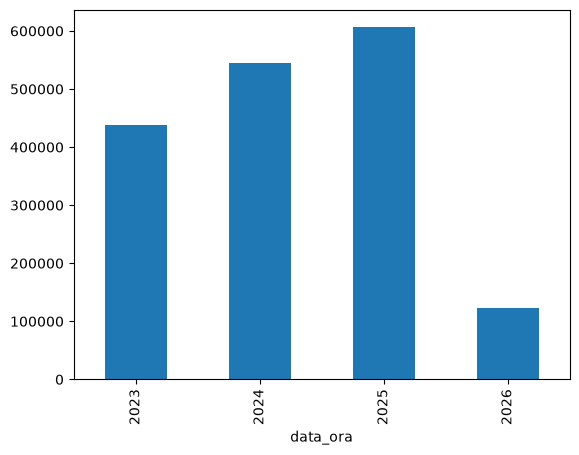

In [3]:
incasso_anno.plot(kind="bar")

L'incasso per anno 2024 è di 544005€, mentre per il 2025 di 606128€. Il 2023,da marzo, ed il 2026, solo gennaio e febbraio, sono anni parziali e non avrebbe molto senso confrontarli.

## D2. Quale brand ha il sell-through più basso?

In [4]:
venduti = vendite.groupby("brand").size()
venduti

brand
Ago&Filo               1902
Borris Calzature        841
Cruciverba             1764
Dipartimento 3         2871
FreePlace Outerwear     738
Grillo                 2246
Hole                    649
Lardoni                2222
Lido Club              1997
Lieve                   604
dtype: int64

In [5]:
ricevuti = o.groupby("brand")["qta_ricevuta"].sum()
ricevuti

brand
Ago&Filo               2115
Borris Calzature       1033
Cruciverba             2080
Dipartimento 3         4145
FreePlace Outerwear    1085
Grillo                 2746
Hole                    786
Lardoni                2768
Lido Club              3552
Lieve                   704
Name: qta_ricevuta, dtype: int64

In [6]:
sell_through = (venduti / ricevuti).sort_values().round(2)
sell_through

brand
Lido Club              0.56
FreePlace Outerwear    0.68
Dipartimento 3         0.69
Lardoni                0.80
Borris Calzature       0.81
Grillo                 0.82
Hole                   0.83
Cruciverba             0.85
Lieve                  0.86
Ago&Filo               0.90
dtype: float64

D2. Il brand con il sell-through più basso è Lido Club con 56% di articoli venduti, mentre il brand con il sell-through più alto è Ago&Filo con il 90%.

## D3. Quali brand hanno più resi per taglia?

In [7]:
resi_taglia = resi[resi["motivo_reso"] == "taglia"]

In [8]:
n_resi_taglia = resi_taglia.groupby("brand").size()
n_resi_taglia

brand
Ago&Filo               12
Borris Calzature       11
Cruciverba             39
Dipartimento 3         39
FreePlace Outerwear    13
Grillo                 25
Hole                   11
Lardoni                73
Lido Club              19
dtype: int64

In [9]:
pct_resi_taglia = (n_resi_taglia / venduti * 100).sort_values(ascending=False).round(2)
pct_resi_taglia

brand
Lardoni                3.29
Cruciverba             2.21
FreePlace Outerwear    1.76
Hole                   1.69
Dipartimento 3         1.36
Borris Calzature       1.31
Grillo                 1.11
Lido Club              0.95
Ago&Filo               0.63
Lieve                   NaN
dtype: float64

D3. I brand che hanno più resi per taglia sono Lardoni con il 3,29% e Cruciverba con il 2,21%, i due brand che vestono piccolo.

## D4. Quale brand ha più resi per difetto?

In [10]:
resi_difetto = resi[resi["motivo_reso"] == "difetto"]

In [11]:
n_resi_difetto = resi_difetto.groupby("brand").size()
n_resi_difetto

brand
Ago&Filo                7
Borris Calzature        1
Cruciverba              2
Dipartimento 3         35
FreePlace Outerwear     1
Grillo                 10
Hole                    4
Lardoni                12
Lido Club              12
Lieve                   3
dtype: int64

In [12]:
pct_resi_difetto = (n_resi_difetto / venduti * 100).sort_values(ascending=False).round(2)
pct_resi_difetto

brand
Dipartimento 3         1.22
Hole                   0.62
Lido Club              0.60
Lardoni                0.54
Lieve                  0.50
Grillo                 0.45
Ago&Filo               0.37
FreePlace Outerwear    0.14
Borris Calzature       0.12
Cruciverba             0.11
dtype: float64

D4. Il brand che ha più resi per difetto è Dipartimento 3 con 1,22%, circa il doppio del secondo che è Hole con 0,62% di resi.

## D5. Quante vendite ai clienti abituali hanno uno sconto oltre il tetto del 10%?

In [13]:
abituale = vendite["motivo_sconto"] == "cliente_abituale"
oltre_tetto = vendite["sconto_pct"] > 10

In [14]:
fuori_regola = abituale & oltre_tetto
fuori_regola.sum()

np.int64(12)

In [15]:
vendite[fuori_regola][["data_ora", "scontrino", "brand", "prezzo_listino", "sconto_pct", "prezzo_venduto"]]

,data_ora,scontrino,brand,prezzo_listino,sconto_pct,prezzo_venduto
83,2023-03-17 19:39:00,S2023-000060,Dipartimento 3,59.0,20,47.20
625,2023-05-27 18:04:00,S2023-000459,Cruciverba,89.0,30,62.30
1152,2023-06-28 11:03:00,S2023-000831,Lido Club,159.0,20,127.20
3094,2023-10-14 19:51:00,S2023-002239,Lardoni,369.0,25,276.75
5340,2024-02-18 12:14:00,S2024-001053,Lido Club,39.0,30,27.30
5595,2024-03-04 16:58:00,S2024-001239,Lieve,259.0,20,207.20
6249,2024-06-04 18:06:00,S2024-001738,Ago&Filo,89.0,20,71.20
8052,2024-08-12 18:42:00,S2024-003029,Hole,139.0,30,97.30
9239,2024-12-16 18:33:00,S2024-003897,Dipartimento 3,119.0,30,83.30
11085,2025-03-16 19:13:00,S2025-001259,Dipartimento 3,49.0,20,39.20


D5. L vendite a clienti abituali con sconto oltre il tetto del 10% sono 12, con sconti tra il 20% ed il 30%. Sono anomalie da segnalare, non da pulire: il dato è scritto bene, è la regola che è stata violata.